# Commuting in French cities: comparison

Reads the summary tables written by the per-city notebooks (`commuting_<city>.ipynb`, all with the same rule, months and thresholds)
and puts them side by side: panel sizes, how many residents get a work cell and why not, where residents work, and commute distances.
Run the city notebooks first; a city without results is skipped.

In [1]:
import os
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

PERIOD = "2024-05_2024-06"   # results of the two-month run of the city notebooks
COUNTRY = "FRA"
CITIES  = {"DEU": ["munich", "berlin", "hamburg", "frankfurt", "cologne"], "FRA": ["paris", "lyon", "marseille", "nice"]}[COUNTRY]
SCRATCH = Path(f"/scratch/project_2022768/{os.environ['USER']}/locomizer")
ACCENT = "#2A6DD9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e7eb",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})

res = {}
for key in CITIES:
    d = SCRATCH / "results" / COUNTRY / f"{key}_{PERIOD}"
    if not (d / "counts.csv").exists():
        print("no results yet for", key); continue
    res[key] = {f.stem: pd.read_csv(f) for f in d.glob("*.csv")}
    res[key]["counts"] = pd.read_csv(d / "counts.csv", index_col=0).iloc[:, 0]
names = {key: res[key]["meta"].city.iloc[0] for key in res}
print("cities with results:", list(names.values()))

cities with results: ['Paris', 'Lyon', 'Marseille', 'Nice']


## 1. Panel size per city

In [2]:
rows = []
for key, r in res.items():
    c, m = r["counts"], r["meta"].iloc[0]
    rows.append({"city": names[key], "FUA km²": m.fua_km2, "city km²": m.city_km2,
                 "FUA residents": c["FUA residents"], "with work cell": c["FUA residents with a work cell"],
                 "share with work cell": f"{100*c['FUA residents with a work cell']/c['FUA residents']:.0f}%",
                 "commuters (home or work in FUA)": c["commuters with home or work in the FUA"],
                 "city residents": c["city residents"], "workers in the city": c["workers in the city (any home)"]})
panel = pd.DataFrame(rows).set_index("city"); panel

,FUA km²,city km²,FUA residents,with work cell,share with work cell,commuters (home or work in FUA),city residents,workers in the city
city,,,,,,,,
Paris,18172,2021,316488,187672,59%,193381,241584,151406
Lyon,4127,297,33536,20119,60%,22572,15326,11112
Marseille,3486,356,32275,20661,64%,22682,14773,10226
Nice,1762,144,12470,8120,65%,9018,9256,6238


## 2. Why residents have no work cell (share of FUA residents)

In [3]:
reasons = pd.concat([r["reasons"].assign(city=names[k]) for k, r in res.items()])
reasons["reason"] = reasons.reason.str[2:]
tab = reasons.pivot(index="reason", columns="city", values="pct_of_residents").fillna(0).round(1)
tab

city,Lyon,Marseille,Nice,Paris
reason,,,,
"away from home, but scattered over cells",25.6,23.4,21.9,26.2
daytime signals only at the home cell,13.7,12.0,12.4,14.1
has work cell in FUA,55.6,59.3,54.9,57.6
has work cell outside FUA,4.4,4.7,10.2,1.7
no 09-17 signals on enough working days,0.6,0.5,0.6,0.5
seen on too few working days,0.0,0.0,0.0,0.0


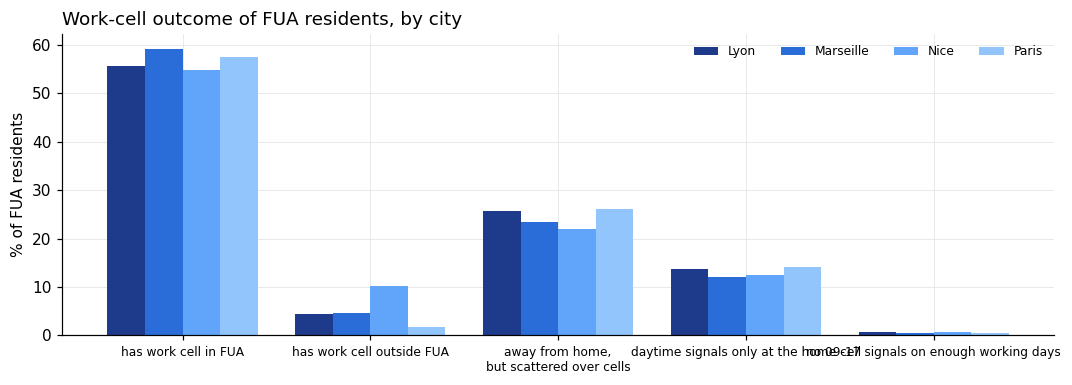

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
order = ["has work cell in FUA", "has work cell outside FUA", "away from home, but scattered over cells", "daytime signals only at the home cell", "no 09-17 signals on enough working days"]
order = [o for o in order if o in tab.index]
x = np.arange(len(order)); w = 0.8 / max(len(tab.columns), 1)
shades = ["#1e3a8a", "#2A6DD9", "#60a5fa", "#93c5fd", "#bfdbfe"]
for i, city in enumerate(tab.columns):
    ax.bar(x + i * w - 0.4 + w / 2, tab.loc[order, city], width=w, color=shades[i % len(shades)], label=city)
ax.set_xticks(x); ax.set_xticklabels([o.replace(", ", ",\n") for o in order], fontsize=8)
ax.set_ylabel("% of FUA residents"); ax.set_title("Work-cell outcome of FUA residents, by city", loc="left"); ax.legend(frameon=False, ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

## 3. Where do city residents work, and where do city workers live?

In [5]:
rows = []
for key, r in res.items():
    c = r["counts"]
    rows.append({"city": names[key],
                 "city residents with work cell": c["city residents with a work cell"],
                 "of which work inside the city": f"{100*c['  ... working inside the city']/c['city residents with a work cell']:.0f}%",
                 "workers in the city": c["workers in the city (any home)"],
                 "of which live inside the city": f"{100*c['  ... working inside the city']/c['workers in the city (any home)']:.0f}%"})
pd.DataFrame(rows).set_index("city")

,city residents with work cell,of which work inside the city,workers in the city,of which live inside the city
city,,,,
Paris,141877,93%,151406,88%
Lyon,8740,82%,11112,64%
Marseille,9315,86%,10226,78%
Nice,5953,78%,6238,75%


## 4. Commute distance (km between home and work cell centres, home and work both in the metro)


In [6]:
dist = pd.concat([r["distance"].assign(city=names[k]) for k, r in res.items()])
pooled = dist[dist["group"] == "home and work in metro"].set_index("city")[["count", "25%", "50%", "75%"]]
missing = [c for c in names.values() if c not in pooled.index]
if missing: print("no pooled distance row yet, re-run the city notebook for:", missing)
pooled.reindex(names.values()).round(1)


,count,25%,50%,75%
city,,,,
Paris,182243.0,0.9,5.0,13.0
Lyon,18641.0,1.5,4.6,10.5
Marseille,19145.0,0.9,3.4,9.5
Nice,6849.0,1.0,2.5,5.7


## 5. Strongest district-to-district flows per city

In [7]:
pd.concat([r["district_flows"].head(5).assign(city=names[k]) for k, r in res.items()]).set_index(["city", "home_district", "work_district"])

users
city      home_district           work_district           
Paris     Seine-Saint-Denis       Paris               6010
          Val-de-Marne            Paris               4470
          Hauts-de-Seine          Paris               3878
          Val-d’Oise              Paris               2601
                                  Seine-Saint-Denis   2179
Lyon      Isère                   Rhône               1292
          Ain                     Rhône               1005
          Rhône                   Isère                410
                                  Ain                  401
          Loire                   Rhône                339
Marseille Var                     Bouches-du-Rhône     662
          Vaucluse                Bouches-du-Rhône     257
          Bouches-du-Rhône        Var                  240
                                  Vaucluse             157
          Alpes-de-Haute-Provence Bouches-du-Rhône     100
Nice      Var                     Alpes-Maritimes      101
          Alpes-Maritimes         Var                   39
                                  Bouches-du-Rhône      25
          Bouches-du-Rhône        Alpes-Maritimes       20
          Hauts-de-Seine          Alpes-Maritimes       12